# Oral Cancer Detection using CNNs (Transfer Learning)

Four-class classification of oral cavity photographs — **Healthy / Benign / OPMD / OCA** — comparing
MobileNetV2, DenseNet121 and an ensemble of the two. The models also learn where the lesion is and
take the patient's age, gender and habits as extra input.

**Setup:** `pip install -r requirements.txt`, then copy the dataset files (`Images.zip`,
`Imagewise_data.csv`, `Patientwise_data.csv`, `Annotation.json`) into the `data` folder next to this
notebook. See the README for training on an NVIDIA GPU.

> Research/educational project only. This is not a medical device and must not be used for diagnosis.

In [1]:
import gc
import json
import os
import warnings
import zipfile
from pathlib import Path

# TensorFlow cannot use the GPU on native Windows, so when PyTorch with CUDA is installed Keras runs on
# PyTorch instead (same code, same saved models). Without it everything runs on TensorFlow as before.
# TensorFlow is still used for loading and augmenting the images in both cases.
if "KERAS_BACKEND" not in os.environ:
    try:
        import torch
        os.environ["KERAS_BACKEND"] = "torch" if torch.cuda.is_available() else "tensorflow"
    except ImportError:
        os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
from PIL import Image, ImageDraw
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report, f1_score, roc_auc_score, roc_curve
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore", category=UserWarning, module="keras")

SEED = 42
keras.utils.set_random_seed(SEED)
if keras.backend.backend() == "torch":
    print("Keras", keras.__version__, "on PyTorch | GPU:", torch.cuda.get_device_name(0))
else:
    print("Keras", keras.__version__, "on TensorFlow | GPUs:", tf.config.list_physical_devices("GPU"))

Keras 3.15.1 on PyTorch | GPU: NVIDIA GeForce RTX 3060


## Configuration

In [2]:
# Dataset location: the "data" folder next to this notebook, or set the ORAL_DATA_DIR environment variable.
# Put the files from Zenodo there as downloaded: Images.zip (or an extracted Images folder),
# Imagewise_data.csv, Patientwise_data.csv and Annotation.json (optional, used to crop to the mouth).
DATA_DIR = Path(os.environ.get("ORAL_DATA_DIR", "data"))
IMAGE_FOLDER = DATA_DIR / "Images"


def find_file(name):
    """Find a file in DATA_DIR ignoring upper/lower case (Imagewise_Data.csv vs Imagewise_data.csv)."""
    if DATA_DIR.is_dir():
        for p in DATA_DIR.iterdir():
            if p.name.lower() == name.lower():
                return p
    return DATA_DIR / name


images_zip = find_file("Images.zip")
if not IMAGE_FOLDER.exists() and images_zip.exists():
    print("Extracting", images_zip, "...")
    with zipfile.ZipFile(images_zip) as zf:
        zf.extractall(IMAGE_FOLDER)

IMAGEWISE_CSV = find_file("Imagewise_Data.csv")
PATIENTWISE_CSV = find_file("Patientwise_Data.csv")
ANNOTATION_JSON = find_file("Annotation.json")

missing = [str(p) for p in (IMAGE_FOLDER, IMAGEWISE_CSV, PATIENTWISE_CSV) if not p.exists()]
if missing:
    raise FileNotFoundError(
        f"Dataset not found in {DATA_DIR.resolve()}.\n"
        "Copy Images.zip, Imagewise_data.csv and Patientwise_data.csv into that folder "
        "(or set ORAL_DATA_DIR to where they are).\nMissing:\n  " + "\n  ".join(missing)
    )

IMG_SIZE = 224
DECODE_RATIO = 4      # the photos are 8-16 megapixels; decode them at 1/4 size (much faster)
CROP_MARGIN = 0.05    # extra border kept around the oral-cavity box
BATCH_SIZE = 32
LESION_GRID = 7       # the lesion map is predicted on a 7x7 grid (the backbones' output resolution)
LESION_LOSS_WEIGHT = 1.0
CLASS_NAMES = ["Healthy", "Benign", "OPMD", "OCA"]
NUM_CLASSES = len(CLASS_NAMES)
label_map = {name: i for i, name in enumerate(CLASS_NAMES)}

# ORAL_SMOKE=1 runs one epoch per stage, just to check the pipeline end to end.
SMOKE_TEST = os.environ.get("ORAL_SMOKE") == "1"
HEAD_EPOCHS = 1 if SMOKE_TEST else 10       # stage 1: train the new classification head
FINE_TUNE_EPOCHS = 1 if SMOKE_TEST else 40  # stage 2: fine-tune the backbone
HEAD_LR = 1e-3
FINE_TUNE_LR = 1e-4
FINE_TUNE_LAYERS = None   # how many of the backbone's last layers to fine-tune (None = all)

# 5-fold cross-validation at the end of the notebook: trains everything five more times, so by default
# it only runs when a GPU is used. Set ORAL_CV=1 / ORAL_CV=0 to force it on or off.
ON_GPU = keras.backend.backend() == "torch" or bool(tf.config.list_physical_devices("GPU"))
RUN_CV = os.environ.get("ORAL_CV", "1" if ON_GPU else "0") == "1"
CV_FOLDS = 2 if SMOKE_TEST else 5

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

## Load the metadata

In [3]:
img_data = pd.read_csv(IMAGEWISE_CSV)
patient_data = pd.read_csv(PATIENTWISE_CSV)
img_data.columns = img_data.columns.str.strip()
patient_data.columns = patient_data.columns.str.strip()

print(img_data.head())
print(patient_data.head())

  Image Name Category Clinical Diagnosis  Lesion Annotation Count
0    R-01-01     OPMD        Leukoplakia                        1
1    R-01-02     OPMD        Leukoplakia                        1
2    R-01-03   Benign      Coated Tongue                        1
3    R-02-01   Benign                VBD                        1
4    R-02-02   Benign                VBD                        1
  Patient ID  Age Gender Smoking Chewing_Betel_Quid Alcohol  Image Count
0       R-01   63      M      No                 No      No            3
1       R-02   17      F      No                 No      No            8
2       R-03   70      M      No                 No      No            5
3       R-04   45      M      No                 No      No            5
4       R-05   46      M      No                Yes      No            2


In [4]:
# Match each row to its image file (any .jpg/.jpeg, case-insensitive, also inside subfolders).
image_index = {
    p.stem.lower(): str(p)
    for p in IMAGE_FOLDER.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg"}
}
img_data["Image Name"] = img_data["Image Name"].astype(str).str.strip()
img_data["path"] = img_data["Image Name"].str.lower().map(image_index)
img_data["label"] = img_data["Category"].astype(str).str.strip().map(label_map)

n_before = len(img_data)
no_file = img_data["path"].isna()
no_label = img_data["label"].isna()
if no_file.any():
    print(f"WARNING: {no_file.sum()} rows have no image file, e.g. {img_data.loc[no_file, 'Image Name'].head(5).tolist()}")
if no_label.any():
    print(f"WARNING: {no_label.sum()} rows have an unknown category: {img_data.loc[no_label, 'Category'].unique().tolist()}")
img_data = img_data[~(no_file | no_label)].reset_index(drop=True)
img_data["label"] = img_data["label"].astype("int32")

# The patient ID is the first two parts of the image name: "R-01-03" -> "R-01", "C-10-12-5" -> "C-10".
img_data["patient_id"] = img_data["Image Name"].str.split("-").str[:2].str.join("-")
unknown_patients = set(img_data["patient_id"]) - set(patient_data["Patient ID"].astype(str).str.strip())
if unknown_patients:
    print(f"WARNING: {len(unknown_patients)} patient IDs are not in the patient table, e.g. {sorted(unknown_patients)[:5]}")

# Phone photos often store their rotation in an EXIF tag instead of rotating the pixels. TensorFlow ignores
# that tag, so read it here and rotate when loading (the annotation boxes refer to the upright image).
def exif_rot90(path):
    """Number of counter-clockwise 90-degree turns needed to make the image upright."""
    with Image.open(path) as im:
        return {3: 2, 6: 3, 8: 1}.get(im.getexif().get(274, 1), 0)


img_data["rot90"] = img_data["path"].map(exif_rot90).astype("int32")

# Oral-cavity bounding boxes [x, y, width, height] from Annotation.json (COCO format).
# [0, 0, 0, 0] means "no box - use the whole photo".
NO_BOX = [0.0, 0.0, 0.0, 0.0]
cavity_boxes = {}
if ANNOTATION_JSON.exists():
    with open(ANNOTATION_JSON, encoding="utf-8") as f:
        coco = json.load(f)
    cavity_ids = {c["id"] for c in coco["categories"] if c["name"].strip().lower() == "oral cavity"}
    stems = {im["id"]: Path(im["file_name"]).stem.lower() for im in coco["images"]}
    for ann in coco["annotations"]:
        if ann["category_id"] not in cavity_ids:
            continue
        x, y, w, h = ann["bbox"]
        key = stems[ann["image_id"]]
        if key in cavity_boxes:          # more than one box: use the area covering both
            px, py, pw, ph = cavity_boxes[key]
            x0, y0 = min(x, px), min(y, py)
            w, h = max(x + w, px + pw) - x0, max(y + h, py + ph) - y0
            x, y = x0, y0
        cavity_boxes[key] = [float(x), float(y), float(w), float(h)]
else:
    print("Annotation.json not found - training on the whole photos instead of oral-cavity crops")
img_data["box"] = [cavity_boxes.get(name.lower(), NO_BOX) for name in img_data["Image Name"]]
print(f"Oral-cavity boxes found for {sum(b != NO_BOX for b in img_data['box'])} of {len(img_data)} images;"
      f" {(img_data['rot90'] > 0).sum()} images need rotating")

print(f"Using {len(img_data)} of {n_before} images from {img_data['patient_id'].nunique()} patients")
print(img_data["Category"].value_counts())

Oral-cavity boxes found for 2999 of 3000 images; 145 images need rotating
Using 3000 of 3000 images from 714 patients
Category
OPMD       1394
Benign      748
Healthy     729
OCA         129
Name: count, dtype: int64


## Lesion outlines and patient risk factors

Two extra sources of information are used during training:

* **Lesion outlines** from `Annotation.json`. A typical lesion covers under a tenth of the mouth, so
  the models are also trained to mark where the lesion is. The outlines are only needed for
  training - a new photo needs no outline.
* **Patient risk factors** (age, gender, smoking, betel quid chewing, alcohol) from the patient table,
  given to the models next to the photo.

In [5]:
def upright_size(path, rot90):
    """(width, height) of the photo after it has been rotated upright."""
    with Image.open(path) as im:
        width, height = im.size
    return (height, width) if rot90 in (1, 3) else (width, height)


def crop_rect(box, size):
    """The crop rectangle (x0, y0, x1, y1) that load_image uses, in full-size pixels."""
    width, height = size
    x, y, w, h = box
    if w <= 1 or h <= 1:
        return 0.0, 0.0, float(width), float(height)
    x0 = min(max(x - CROP_MARGIN * w, 0), width - 2)
    y0 = min(max(y - CROP_MARGIN * h, 0), height - 2)
    x1 = min(max(x + (1 + CROP_MARGIN) * w, x0 + 2), width)
    y1 = min(max(y + (1 + CROP_MARGIN) * h, y0 + 2), height)
    return x0, y0, x1, y1


lesion_polygons = {}
if ANNOTATION_JSON.exists():
    lesion_ids = {c["id"] for c in coco["categories"] if c["name"].strip().lower() == "lesion"}
    for ann in coco["annotations"]:
        if ann["category_id"] in lesion_ids and len(ann["segmentation"]) >= 6:
            lesion_polygons.setdefault(stems[ann["image_id"]], []).append(ann["segmentation"])


def lesion_mask(name, box, size):
    """Lesion outlines drawn as a 0/255 mask in the cropped, resized image frame."""
    x0, y0, x1, y1 = crop_rect(box, size)
    canvas = Image.new("L", (IMG_SIZE, IMG_SIZE), 0)
    draw = ImageDraw.Draw(canvas)
    for polygon in lesion_polygons.get(name.lower(), []):   # flat list [x1, y1, x2, y2, ...]
        points = [((polygon[i] - x0) / (x1 - x0) * IMG_SIZE, (polygon[i + 1] - y0) / (y1 - y0) * IMG_SIZE)
                  for i in range(0, len(polygon) - 1, 2)]
        draw.polygon(points, fill=255)
    return np.asarray(canvas, dtype="uint8")


lesion_masks = np.stack([
    lesion_mask(name, box, upright_size(path, rot))
    for name, box, path, rot in zip(img_data["Image Name"], img_data["box"], img_data["path"], img_data["rot90"])
])


def _flag(value):
    """Accept 1/0, True/False or 'Yes'/'No'."""
    if isinstance(value, str):
        return 1 if value.strip().lower() in {"yes", "y", "1", "true"} else 0
    return int(bool(value))


def risk_vector(age=50, gender="M", tobacco=0, betel=0, alcohol=0):
    """The patient information given to the model: [age/100, male, smoking, betel quid, alcohol]."""
    male = 1.0 if str(gender).strip().upper().startswith("M") else 0.0
    return [float(age) / 100.0, male, float(_flag(tobacco)), float(_flag(betel)), float(_flag(alcohol))]


patients = patient_data.assign(**{"Patient ID": patient_data["Patient ID"].astype(str).str.strip()})
patients = patients.drop_duplicates("Patient ID").set_index("Patient ID")


def patient_risk_vector(patient_id):
    if patient_id not in patients.index:
        return risk_vector()
    row = patients.loc[patient_id]
    return risk_vector(row["Age"], row["Gender"], row["Smoking"], row["Chewing_Betel_Quid"], row["Alcohol"])


risk_vectors = np.array([patient_risk_vector(pid) for pid in img_data["patient_id"]], dtype="float32")
img_data["row"] = np.arange(len(img_data))   # position in lesion_masks / risk_vectors

print(f"Lesion outlines found for {sum(name.lower() in lesion_polygons for name in img_data['Image Name'])}"
      f" of {len(img_data)} images")
print("Average share of the image covered by lesion:",
      {name: round(float(lesion_masks[(img_data['label'] == i).to_numpy()].mean() / 255), 3)
       for i, name in enumerate(CLASS_NAMES)})

Lesion outlines found for 2271 of 3000 images
Average share of the image covered by lesion: {'Healthy': 0.0, 'Benign': 0.109, 'OPMD': 0.224, 'OCA': 0.074}


## Train / validation / test split

The split is made **by patient**, so photos of the same mouth never appear in both training and
evaluation data, and it is made **before** any class balancing. (Oversampling the OCA class before
splitting, as in the first version of this notebook, puts copies of the same image in both the
training and the test set and inflates the OCA scores.)

A separate validation set is used for early stopping and model selection; the test set is only
used for the final report.

In [6]:
def group_split(df, n_splits, seed):
    """Hold out roughly 1/n_splits of the patients, stratified by label."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest_idx, held_idx = next(sgkf.split(df, df["label"], groups=df["patient_id"]))
    return df.iloc[rest_idx].reset_index(drop=True), df.iloc[held_idx].reset_index(drop=True)


trainval_df, test_df = group_split(img_data, 5, SEED)   # ~20% test
train_df, val_df = group_split(trainval_df, 5, SEED)    # ~16% validation, ~64% train

assert not set(train_df["patient_id"]) & set(test_df["patient_id"])
assert not set(train_df["patient_id"]) & set(val_df["patient_id"])
assert not set(val_df["patient_id"]) & set(test_df["patient_id"])

split_counts = pd.DataFrame({
    name: df["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
    for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]
})
split_counts.index = CLASS_NAMES
print(split_counts)

         train  val  test
Healthy    467  116   146
Benign     479  120   149
OPMD       892  223   279
OCA         82   21    26


In [7]:
# Handle class imbalance with class weights computed on the training set only.
present = np.unique(train_df["label"])
weights = compute_class_weight("balanced", classes=present, y=train_df["label"].to_numpy())
class_weight = {int(c): float(w) for c, w in zip(present, weights)}
print("Class weights:", {CLASS_NAMES[c]: round(w, 2) for c, w in class_weight.items()})

Class weights: {'Healthy': 1.03, 'Benign': 1.0, 'OPMD': 0.54, 'OCA': 5.85}


## Input pipeline

One `load_image` function is used for training, evaluation and single-image prediction, so the
model always sees images prepared the same way: upright and cropped to the oral cavity, so the
mouth fills the frame instead of lips, skin and background. Images stay in the raw 0–255 range here; the
backbone-specific normalisation lives inside each model.

The lesion mask travels with the photo as a fourth channel, so flips, rotations and zooms move
both together.

In [8]:
def load_image(path, box=NO_BOX, rot90=0):
    """Read a photo, make it upright, crop it to the oral-cavity box (if any) and resize it.

    Returns a float32 RGB tensor (IMG_SIZE, IMG_SIZE, 3) in [0, 255].
    box is [x, y, width, height] in pixels of the upright full-size photo; all zeros = whole photo.
    """
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3, ratio=DECODE_RATIO, try_recover_truncated=True)
    img = tf.image.rot90(img, k=rot90)

    height = tf.cast(tf.shape(img)[0], tf.float32)
    width = tf.cast(tf.shape(img)[1], tf.float32)
    x, y, w, h = tf.unstack(tf.cast(box, tf.float32) / DECODE_RATIO)
    has_box = tf.logical_and(w > 1, h > 1)
    x0 = tf.where(has_box, tf.clip_by_value(x - CROP_MARGIN * w, 0.0, width - 2), 0.0)
    y0 = tf.where(has_box, tf.clip_by_value(y - CROP_MARGIN * h, 0.0, height - 2), 0.0)
    x1 = tf.where(has_box, tf.clip_by_value(x + (1 + CROP_MARGIN) * w, x0 + 2, width), width)
    y1 = tf.where(has_box, tf.clip_by_value(y + (1 + CROP_MARGIN) * h, y0 + 2, height), height)
    img = tf.image.crop_to_bounding_box(
        img, tf.cast(y0, tf.int32), tf.cast(x0, tf.int32), tf.cast(y1 - y0, tf.int32), tf.cast(x1 - x0, tf.int32)
    )

    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)
    return tf.clip_by_value(img, 0.0, 255.0)


# Fairly strong augmentation: with ~1,900 training photos the models overfit quickly without it.
geometric_augment = [                       # applied to the photo and its lesion mask together
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.12),            # about +/- 45 degrees
    layers.RandomZoom((-0.3, 0.1)),         # mostly zoom in
    layers.RandomTranslation(0.1, 0.1),
]
colour_augment = [                          # applied to the photo only
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.2),
]


def make_dataset(df, training=False, class_weight=None):
    """Batches of ({"image", "risk"}, {"label", "lesion_map"}); training batches also carry class weights."""
    rows = df["row"].to_numpy()
    weight_table = tf.constant([(class_weight or {}).get(i, 1.0) for i in range(NUM_CLASSES)], tf.float32)

    def load(path, box, rot90, mask, risk, label):
        image = tf.cast(load_image(path, box, rot90), tf.uint8)
        return tf.concat([image, mask[..., tf.newaxis]], axis=-1), risk, label

    def finish(image_and_mask, risk, label):
        x = tf.cast(image_and_mask, tf.float32)
        if training:
            for layer in geometric_augment:
                x = layer(x, training=True)
        image, mask = x[..., :3], x[..., 3:]
        if training:
            for layer in colour_augment:
                image = layer(image, training=True)
        image = tf.clip_by_value(image, 0.0, 255.0)
        # Lesion map target: the share of each grid cell that is covered by lesion.
        cell = IMG_SIZE // LESION_GRID
        lesion_map = tf.clip_by_value(tf.nn.avg_pool2d(mask, cell, cell, "VALID") / 255.0, 0.0, 1.0)
        lesion_map = tf.reshape(lesion_map, (-1, LESION_GRID * LESION_GRID))
        inputs = {"image": image, "risk": risk}
        targets = {"label": label, "lesion_map": lesion_map}
        if training:
            sample_weights = {"label": tf.gather(weight_table, label),
                              "lesion_map": tf.ones_like(tf.cast(label, tf.float32))}
            return inputs, targets, sample_weights
        return inputs, targets

    ds = tf.data.Dataset.from_tensor_slices((
        df["path"].astype(str).tolist(),
        np.array(df["box"].tolist(), dtype="float32"),
        df["rot90"].to_numpy(dtype="int32"),
        lesion_masks[rows],
        risk_vectors[rows],
        df["label"].to_numpy(dtype="int32"),
    ))
    # Cache the resized images (as uint8 to save memory) so files are decoded only once.
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).map(finish, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, training=True, class_weight=class_weight)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

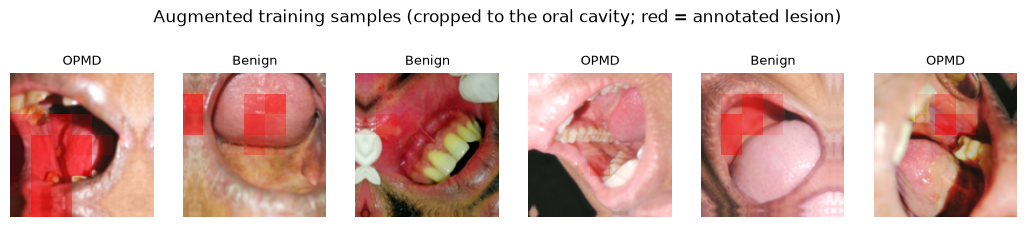

In [9]:
def show_lesion_map(ax, image, lesion_map, title):
    """Draw a photo with a lesion map (true or predicted) laid over it."""
    ax.imshow(np.clip(image, 0, 255).astype("uint8"))
    grid = np.clip(np.reshape(lesion_map, (LESION_GRID, LESION_GRID)), 0, 1)
    ax.imshow(np.zeros_like(grid), cmap="autumn", vmin=0, vmax=1, alpha=0.6 * grid,   # red, stronger = surer
              extent=(0, IMG_SIZE, IMG_SIZE, 0), interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")


inputs, targets, _ = next(iter(train_ds))
fig, axes = plt.subplots(1, 6, figsize=(13, 2.8))
for i, ax in enumerate(axes):
    show_lesion_map(ax, inputs["image"][i].numpy(), targets["lesion_map"][i].numpy(),
                    CLASS_NAMES[int(targets["label"][i])])
fig.suptitle("Augmented training samples (cropped to the oral cavity; red = annotated lesion)")
plt.show()

## Models

Both models use an ImageNet-pretrained backbone. Each backbone gets the input normalisation it was
pretrained with (MobileNetV2: scale to [-1, 1]; DenseNet121: ImageNet mean/std) — feeding both plain
`1/255`-scaled images, as before, hurts transfer learning.

On top of the backbone each model has two outputs:

* `lesion_map` — a 7×7 map of where the lesion is, trained against the annotated outlines;
* `label` — the class, predicted from the average image features, the features averaged over the
  predicted lesion area, and the patient's risk factors.

Training is two-stage: first only the new layers (backbone frozen), then the whole backbone is
fine-tuned with a lower learning rate. BatchNorm layers stay frozen during fine-tuning.

In [10]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406]) * 255.0
IMAGENET_STD = np.array([0.229, 0.224, 0.225]) * 255.0

BACKBONES = {
    "MobileNetV2": (
        keras.applications.MobileNetV2,
        lambda: layers.Rescaling(1.0 / 127.5, offset=-1.0, name="preprocess"),
    ),
    "DenseNet121": (
        keras.applications.DenseNet121,
        lambda: layers.Normalization(mean=IMAGENET_MEAN, variance=IMAGENET_STD ** 2, name="preprocess"),
    ),
}


def build_model(backbone_name):
    constructor, make_preprocess = BACKBONES[backbone_name]
    base = constructor(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    image = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")   # raw RGB, 0-255
    risk = keras.Input((5,), name="risk")                         # see risk_vector()
    features = base(make_preprocess()(image), training=False)     # keep BatchNorm in inference mode

    lesion_grid = layers.Conv2D(1, 1, activation="sigmoid", name="lesion_grid")(features)
    lesion_map = layers.Flatten(name="lesion_map")(lesion_grid)

    whole_image = layers.GlobalAveragePooling2D()(features)
    lesion_area = layers.GlobalAveragePooling2D()(layers.Multiply()([features, lesion_grid]))
    x = layers.Dropout(0.3)(layers.Concatenate()([whole_image, lesion_area]))
    x = layers.Concatenate()([x, layers.Dense(16, activation="relu", name="risk_features")(risk)])
    label = layers.Dense(NUM_CLASSES, activation="softmax", name="label")(x)

    model = keras.Model({"image": image, "risk": risk}, {"label": label, "lesion_map": lesion_map},
                        name=backbone_name)
    return model, base


def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss={"label": "sparse_categorical_crossentropy", "lesion_map": "binary_crossentropy"},
        loss_weights={"label": 1.0, "lesion_map": LESION_LOSS_WEIGHT},
        metrics={"label": ["accuracy"]},
    )


def make_callbacks():
    # Early stopping watches the classification loss on the validation set.
    return [
        keras.callbacks.EarlyStopping(monitor="val_label_loss", mode="min", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_label_loss", mode="min", patience=3, factor=0.3),
    ]


def val_label_loss(model, val_ds):
    return model.evaluate(val_ds, verbose=0, return_dict=True)["label_loss"]


def train_two_stage(backbone_name, train_ds, val_ds, verbose=2):
    model, base = build_model(backbone_name)

    # Stage 1: train the new layers only.
    compile_model(model, HEAD_LR)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=make_callbacks(), verbose=verbose)
    stage1_weights = MODEL_DIR / f"{backbone_name}_stage1.weights.h5"
    model.save_weights(stage1_weights)
    stage1_val_loss = val_label_loss(model, val_ds)

    # Stage 2: fine-tune the backbone (BatchNorm stays frozen).
    base.trainable = True
    if FINE_TUNE_LAYERS is not None:
        for layer in base.layers[:-FINE_TUNE_LAYERS]:
            layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model, FINE_TUNE_LR)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS, callbacks=make_callbacks(),
                   verbose=verbose)

    # Keep the stage-1 weights if fine-tuning did not help.
    if val_label_loss(model, val_ds) > stage1_val_loss:
        print(f"{backbone_name}: fine-tuning did not improve validation loss; keeping stage-1 weights")
        model.load_weights(stage1_weights)
    stage1_weights.unlink(missing_ok=True)

    keys = {"accuracy": "label_accuracy", "val_accuracy": "val_label_accuracy",
            "loss": "label_loss", "val_loss": "val_label_loss"}
    history = {k: h1.history[v] + h2.history[v] for k, v in keys.items()}
    return model, history, len(h1.history["loss"])

## Evaluation helpers

In [11]:
def plot_history(history, fine_tune_start, title):
    plt.figure(figsize=(14, 5))
    for i, metric in enumerate(["accuracy", "loss"]):
        plt.subplot(1, 2, i + 1)
        plt.plot(history[metric], label="Train")
        plt.plot(history["val_" + metric], label="Validation")
        plt.axvline(fine_tune_start - 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
        plt.title(f"{title} - {metric.capitalize()}")
        plt.xlabel("Epoch")
        plt.legend()
    plt.tight_layout()
    plt.show()


ALL_LABELS = list(range(NUM_CLASSES))
OCA = label_map["OCA"]
REFER_CLASSES = [label_map["OPMD"], label_map["OCA"]]   # lesions that should be seen by a specialist


def predict_proba(model, ds):
    """Class probabilities for every image in a dataset."""
    return model.predict(ds, verbose=0)["label"]


def auc(is_positive, score):
    return float(roc_auc_score(is_positive, score)) if 0 < is_positive.sum() < len(is_positive) else float("nan")


def scores(y_true, proba):
    """Four-class scores, plus how well the probabilities rank two yes/no screening questions (AUC)."""
    y_true = np.asarray(y_true)
    y_pred = np.argmax(proba, axis=1)
    is_oca = y_true == OCA
    return {
        "accuracy": float((y_true == y_pred).mean()),
        "macro_f1": f1_score(y_true, y_pred, labels=ALL_LABELS, average="macro", zero_division=0),
        "OCA_recall": float((y_pred[is_oca] == OCA).mean()) if is_oca.any() else float("nan"),
        "referral_AUC": auc(np.isin(y_true, REFER_CLASSES), proba[:, REFER_CLASSES].sum(axis=1)),
        "OCA_AUC": auc(is_oca, proba[:, OCA]),
    }


def evaluate_on_test(val_proba, test_proba, title):
    """Confusion matrix and report from predicted class probabilities; returns the summary scores."""
    y_true = test_df["label"].to_numpy()
    y_pred = np.argmax(test_proba, axis=1)

    cm = confusion_matrix(y_true, y_pred, labels=ALL_LABELS)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix - {title}")
    plt.show()

    print(f"Classification Report - {title}")
    print(classification_report(y_true, y_pred, labels=ALL_LABELS, target_names=CLASS_NAMES, zero_division=0))
    summary = {"val_macro_f1": scores(val_df["label"].to_numpy(), val_proba)["macro_f1"]}
    summary.update({"test_" + k: v for k, v in scores(y_true, test_proba).items()})
    return summary

## MobileNetV2

Epoch 1/10
60/60 - 26s - 438ms/step - label_accuracy: 0.3104 - label_loss: 1.4821 - lesion_map_loss: 0.6371 - loss: 2.1191 - val_label_accuracy: 0.2667 - val_label_loss: 1.5114 - val_lesion_map_loss: 0.5463 - val_loss: 2.0577 - learning_rate: 0.0010
Epoch 2/10
60/60 - 24s - 392ms/step - label_accuracy: 0.3901 - label_loss: 1.2593 - lesion_map_loss: 0.5244 - loss: 1.7837 - val_label_accuracy: 0.4479 - val_label_loss: 1.1557 - val_lesion_map_loss: 0.5091 - val_loss: 1.6648 - learning_rate: 0.0010
Epoch 3/10
60/60 - 14s - 240ms/step - label_accuracy: 0.4573 - label_loss: 1.1361 - lesion_map_loss: 0.5026 - loss: 1.6387 - val_label_accuracy: 0.3833 - val_label_loss: 1.3421 - val_lesion_map_loss: 0.4802 - val_loss: 1.8223 - learning_rate: 0.0010
Epoch 4/10
60/60 - 13s - 216ms/step - label_accuracy: 0.4724 - label_loss: 1.1158 - lesion_map_loss: 0.4911 - loss: 1.6070 - val_label_accuracy: 0.4500 - val_label_loss: 1.2494 - val_lesion_map_loss: 0.4628 - val_loss: 1.7123 - learning_rate: 0.0010


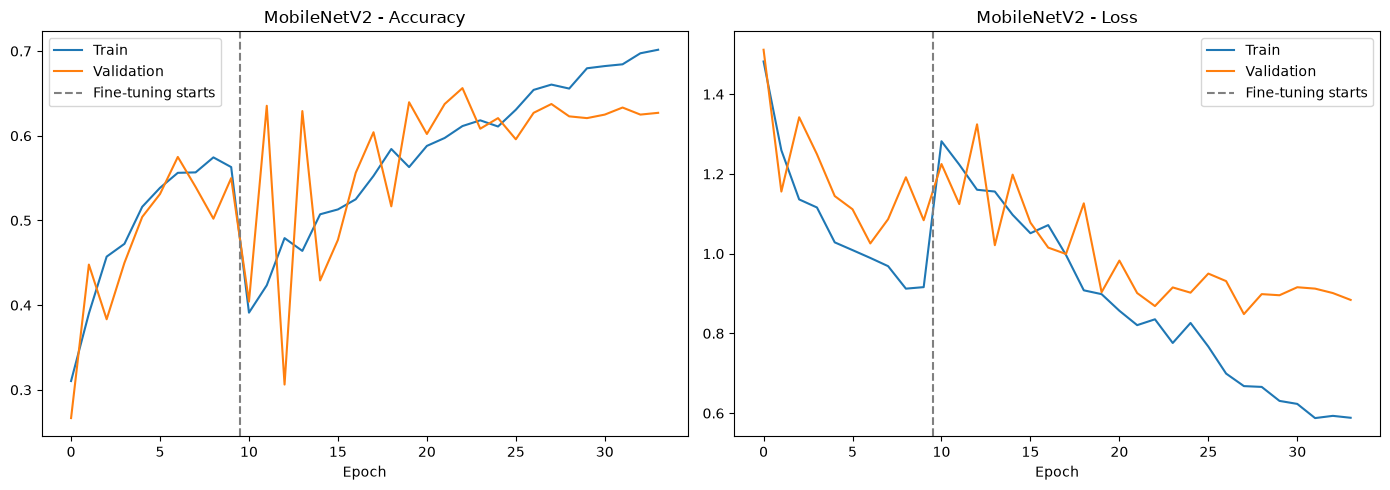

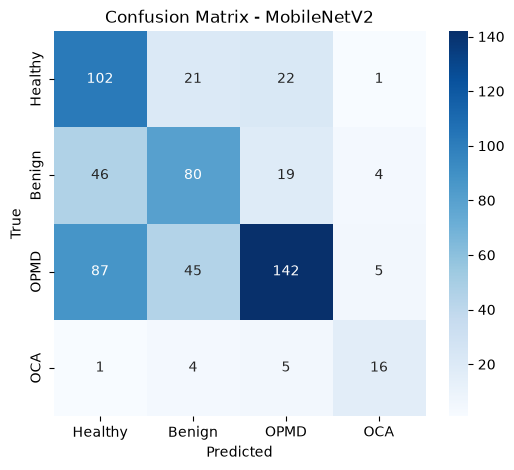

Classification Report - MobileNetV2
              precision    recall  f1-score   support

     Healthy       0.43      0.70      0.53       146
      Benign       0.53      0.54      0.54       149
        OPMD       0.76      0.51      0.61       279
         OCA       0.62      0.62      0.62        26

    accuracy                           0.57       600
   macro avg       0.58      0.59      0.57       600
weighted avg       0.62      0.57      0.57       600



In [12]:
models, histories, results, val_proba, test_proba = {}, {}, {}, {}, {}


def train_and_report(name):
    models[name], histories[name], ft_start = train_two_stage(name, train_ds, val_ds)
    plot_history(histories[name], ft_start, name)
    val_proba[name] = predict_proba(models[name], val_ds)
    test_proba[name] = predict_proba(models[name], test_ds)
    results[name] = evaluate_on_test(val_proba[name], test_proba[name], name)
    models[name].save(MODEL_DIR / f"oral_cancer_{name.lower()}.keras")


train_and_report("MobileNetV2")

## DenseNet121

DenseNet121 connects each layer to all previous layers, which encourages feature reuse and good
gradient flow, and it is widely used in medical image analysis. It is trained with exactly the same
data, head and schedule as MobileNetV2 so the two can be compared fairly.

Epoch 1/10
60/60 - 12s - 194ms/step - label_accuracy: 0.2901 - label_loss: 1.5444 - lesion_map_loss: 0.5440 - loss: 2.0883 - val_label_accuracy: 0.2562 - val_label_loss: 1.4466 - val_lesion_map_loss: 0.4947 - val_loss: 1.9413 - learning_rate: 0.0010
Epoch 2/10
60/60 - 11s - 191ms/step - label_accuracy: 0.3667 - label_loss: 1.3440 - lesion_map_loss: 0.4577 - loss: 1.8016 - val_label_accuracy: 0.4688 - val_label_loss: 1.1963 - val_lesion_map_loss: 0.4003 - val_loss: 1.5966 - learning_rate: 0.0010
Epoch 3/10
60/60 - 12s - 193ms/step - label_accuracy: 0.4083 - label_loss: 1.2851 - lesion_map_loss: 0.4281 - loss: 1.7132 - val_label_accuracy: 0.5146 - val_label_loss: 1.1242 - val_lesion_map_loss: 0.3792 - val_loss: 1.5034 - learning_rate: 0.0010
Epoch 4/10
60/60 - 11s - 189ms/step - label_accuracy: 0.4365 - label_loss: 1.2209 - lesion_map_loss: 0.4104 - loss: 1.6313 - val_label_accuracy: 0.4646 - val_label_loss: 1.2027 - val_lesion_map_loss: 0.3646 - val_loss: 1.5673 - learning_rate: 0.0010


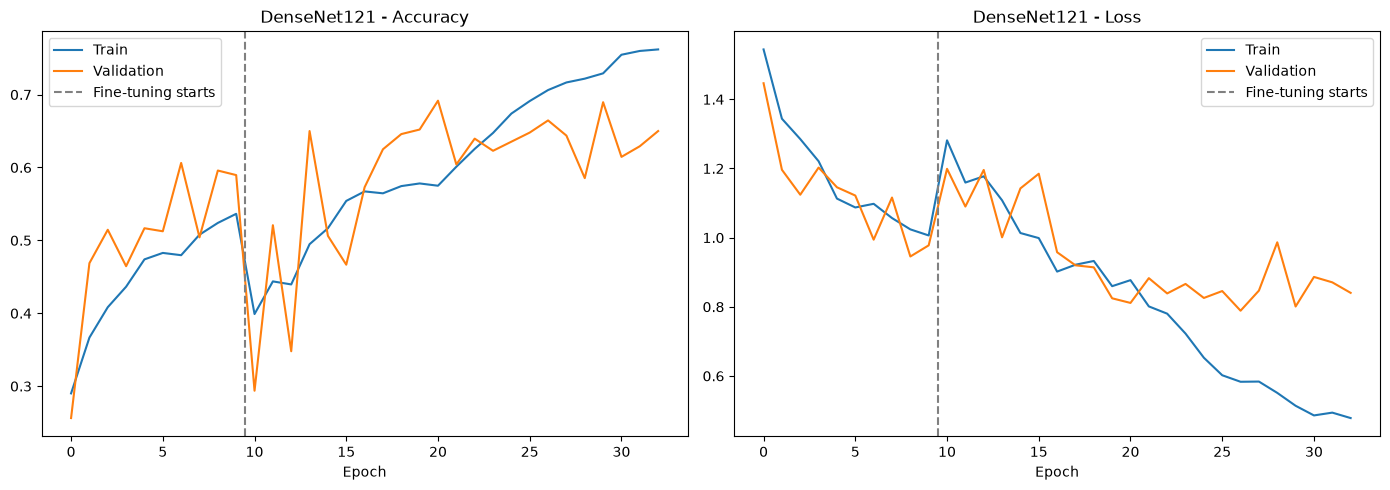

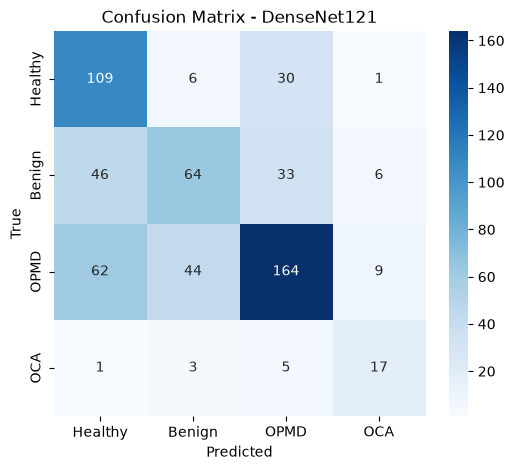

Classification Report - DenseNet121
              precision    recall  f1-score   support

     Healthy       0.50      0.75      0.60       146
      Benign       0.55      0.43      0.48       149
        OPMD       0.71      0.59      0.64       279
         OCA       0.52      0.65      0.58        26

    accuracy                           0.59       600
   macro avg       0.57      0.60      0.57       600
weighted avg       0.61      0.59      0.59       600



In [13]:
train_and_report("DenseNet121")

## Ensemble

The two networks make partly different mistakes, so averaging their predicted probabilities is
usually a little better and more stable than either alone.

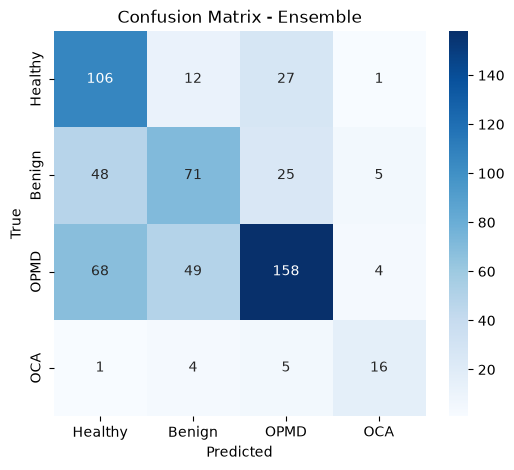

Classification Report - Ensemble
              precision    recall  f1-score   support

     Healthy       0.48      0.73      0.57       146
      Benign       0.52      0.48      0.50       149
        OPMD       0.73      0.57      0.64       279
         OCA       0.62      0.62      0.62        26

    accuracy                           0.58       600
   macro avg       0.59      0.60      0.58       600
weighted avg       0.61      0.58      0.59       600



In [14]:
image_in = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
risk_in = keras.Input((5,), name="risk")
member_outputs = [models[name]({"image": image_in, "risk": risk_in}) for name in BACKBONES]
models["Ensemble"] = keras.Model(
    {"image": image_in, "risk": risk_in},
    {key: layers.Average(name=key)([out[key] for out in member_outputs]) for key in ("label", "lesion_map")},
    name="Ensemble",
)
val_proba["Ensemble"] = (val_proba["MobileNetV2"] + val_proba["DenseNet121"]) / 2
test_proba["Ensemble"] = (test_proba["MobileNetV2"] + test_proba["DenseNet121"]) / 2
results["Ensemble"] = evaluate_on_test(val_proba["Ensemble"], test_proba["Ensemble"], "Ensemble")

## Comparison

The model used for prediction below is chosen by **validation** macro-F1 (not test), so the test
numbers stay an unbiased estimate. Macro-F1 and OCA recall matter more than accuracy here because
the classes are imbalanced and missing a cancer is the costliest error.

             val_macro_f1  test_accuracy  test_macro_f1  test_OCA_recall  test_referral_AUC  test_OCA_AUC
MobileNetV2         0.564          0.567          0.573            0.615              0.759         0.918
DenseNet121         0.600          0.590          0.575            0.654              0.779         0.901
Ensemble            0.610          0.585          0.582            0.615              0.778         0.917


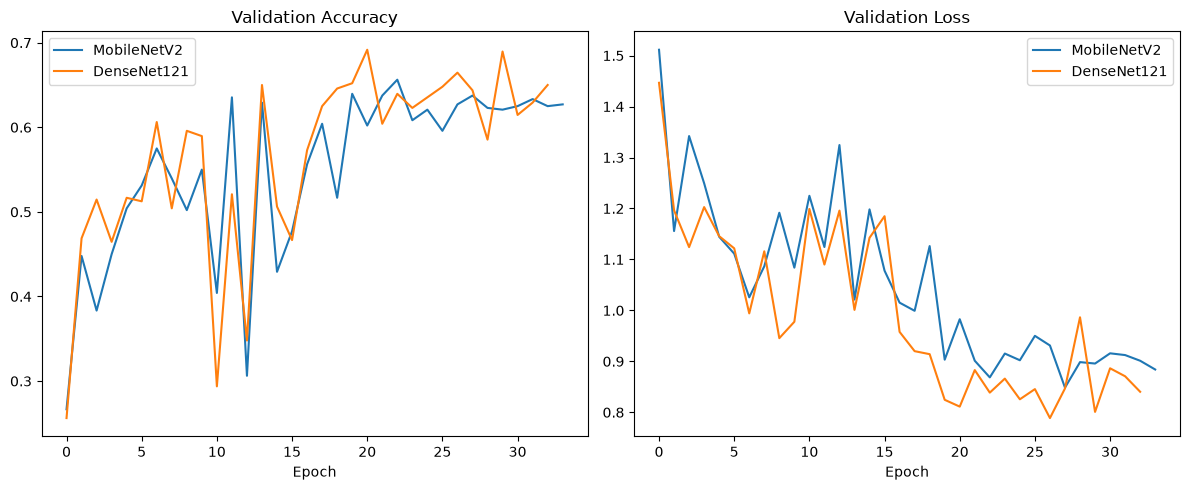

Best model (by validation macro-F1): Ensemble


In [15]:
results_df = pd.DataFrame(results).T.round(3)
print(results_df.to_string())

plt.figure(figsize=(12, 5))
for i, metric in enumerate(["val_accuracy", "val_loss"]):
    plt.subplot(1, 2, i + 1)
    for name, history in histories.items():
        plt.plot(history[metric], label=name)
    plt.title("Validation " + metric.split("_")[1].capitalize())
    plt.xlabel("Epoch")
    plt.legend()
plt.tight_layout()
plt.show()

best_name = results_df["val_macro_f1"].idxmax()
best_model = models[best_name]
best_model.save(MODEL_DIR / "oral_cancer_model.keras")
print("Best model (by validation macro-F1):", best_name)

## Where the model looks

The predicted lesion maps for a few test photos (red = where the model thinks the lesion is),
next to the annotated lesions.

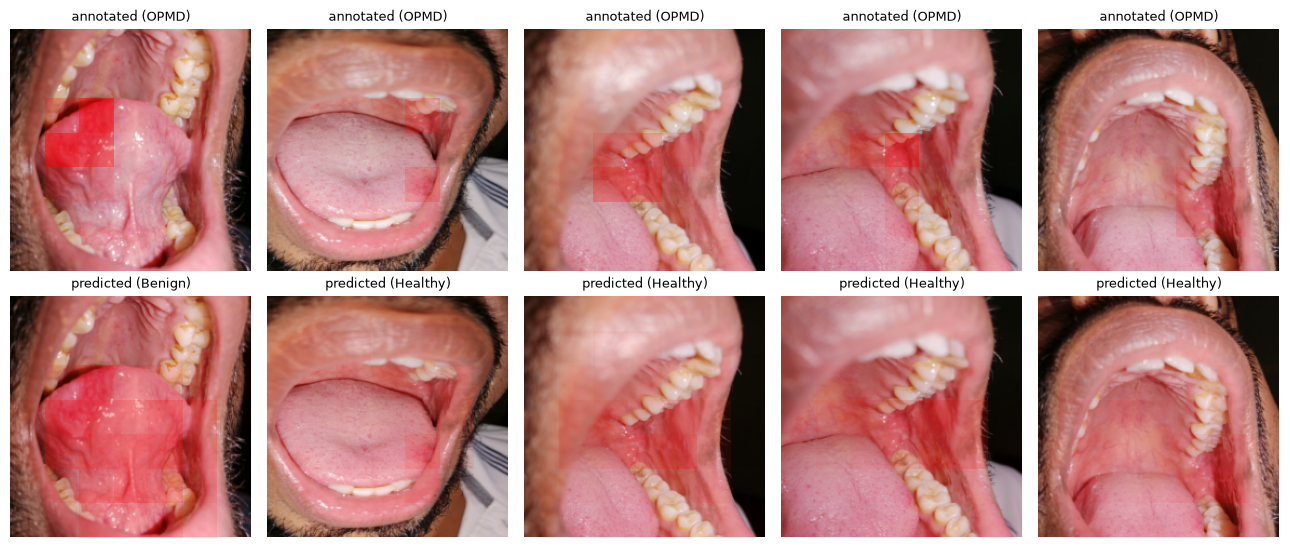

In [16]:
inputs, targets = next(iter(test_ds.unbatch().filter(lambda x, y: y["label"] > 0).batch(5)))
predicted = best_model.predict(inputs, verbose=0)
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for i in range(axes.shape[1]):
    image = inputs["image"][i].numpy()
    true_name = CLASS_NAMES[int(targets["label"][i])]
    predicted_name = CLASS_NAMES[int(np.argmax(predicted["label"][i]))]
    show_lesion_map(axes[0, i], image, targets["lesion_map"][i].numpy(), f"annotated ({true_name})")
    show_lesion_map(axes[1, i], image, predicted["lesion_map"][i], f"predicted ({predicted_name})")
plt.tight_layout()
plt.show()

## Screening view: who needs a specialist?

Telling Healthy from Benign matters little in practice. A screening tool has to answer two yes/no
questions, and both can be read off the same model:

* **Referral** - is this OPMD or OCA (should be seen by a specialist)? Score = P(OPMD) + P(OCA).
* **Suspected cancer** - is this OCA? Score = P(OCA).

The class with the highest probability is a poor way to answer them, because OCA is rare and is
seldom the top class. Instead a threshold on the score is chosen **on the validation set** so that
about 90% of the true cases are caught, and then checked on the test set. Sensitivity = share of
true cases flagged; specificity = share of the others correctly left alone.

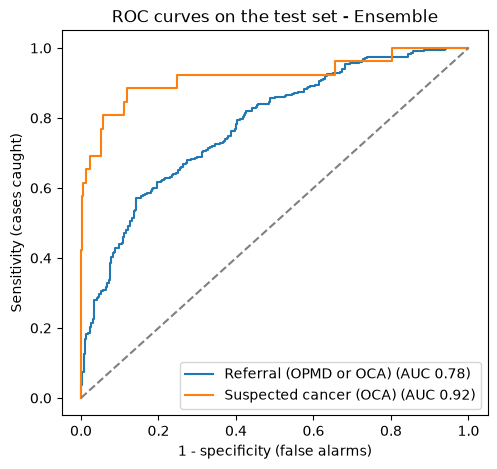

              question  threshold  test_AUC  test_sensitivity  test_specificity  test_cases
Referral (OPMD or OCA)      0.245     0.778             0.803             0.583         305
Suspected cancer (OCA)      0.014     0.917             0.923             0.667          26


In [17]:
TARGET_SENSITIVITY = 0.90
best_val, best_test = val_proba[best_name], test_proba[best_name]
y_val, y_test = val_df["label"].to_numpy(), test_df["label"].to_numpy()

screening = {
    "Referral (OPMD or OCA)": (lambda y: np.isin(y, REFER_CLASSES), lambda p: p[:, REFER_CLASSES].sum(axis=1)),
    "Suspected cancer (OCA)": (lambda y: y == OCA, lambda p: p[:, OCA]),
}
thresholds, screening_rows = {}, []
plt.figure(figsize=(5.5, 5))
for question, (is_case, score) in screening.items():
    val_cases, test_cases = is_case(y_val), is_case(y_test)
    if not val_cases.any() or not test_cases.any() or test_cases.all():
        continue
    # The threshold that flags ~90% of the validation cases.
    thresholds[question] = float(np.quantile(score(best_val)[val_cases], 1 - TARGET_SENSITIVITY))
    flagged = score(best_test) >= thresholds[question]
    screening_rows.append({
        "question": question,
        "threshold": round(thresholds[question], 3),
        "test_AUC": round(auc(test_cases, score(best_test)), 3),
        "test_sensitivity": round(float(flagged[test_cases].mean()), 3),
        "test_specificity": round(float((~flagged[~test_cases]).mean()), 3),
        "test_cases": int(test_cases.sum()),
    })
    fpr, tpr, _ = roc_curve(test_cases, score(best_test))
    plt.plot(fpr, tpr, label=f"{question} (AUC {screening_rows[-1]['test_AUC']:.2f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("1 - specificity (false alarms)")
plt.ylabel("Sensitivity (cases caught)")
plt.title(f"ROC curves on the test set - {best_name}")
plt.legend(loc="lower right")
plt.show()

print(pd.DataFrame(screening_rows).to_string(index=False))

## Lifestyle risk score and combined prediction

In [18]:
def risk_score(tobacco, betel, alcohol):
    score = _flag(tobacco) * 0.4 + _flag(betel) * 0.4 + _flag(alcohol) * 0.2
    if score >= 0.7:
        return "High Risk"
    elif score >= 0.3:
        return "Moderate Risk"
    return "Low Risk"


RECOMMENDATIONS = {
    # class: (message if lifestyle risk is high, message otherwise)
    "OCA": ("Findings suggestive of oral cancer - urgent specialist referral recommended.",) * 2,
    "OPMD": ("Possible pre-malignant lesion and HIGH lifestyle risk - urgent clinical evaluation recommended.",
             "Possible pre-malignant lesion (OPMD) - schedule diagnostic screening."),
    "Benign": ("Lesion appears benign but lifestyle risk is high - monitor regularly and reduce habits.",
               "Lesion appears benign - routine oral care recommended."),
    "Healthy": ("No lesion detected but lifestyle risk is high - preventive counselling advised.",
                "No lesion detected - routine oral care."),
}


def predict_full(image_path, tobacco=0, betel=0, alcohol=0, age=50, gender="M", box=NO_BOX, model=None):
    """Classify one photo. The model was trained on photos cropped to the mouth, so for a new photo either
    pass box=[x, y, width, height] around the oral cavity or use a photo already framed on the mouth."""
    model = model or best_model
    if not os.path.isfile(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = load_image(str(image_path), box, exif_rot90(image_path)).numpy()
    risk_input = np.array([risk_vector(age, gender, tobacco, betel, alcohol)], dtype="float32")
    output = model.predict({"image": image[np.newaxis, ...], "risk": risk_input}, verbose=0)
    pred = output["label"][0]
    class_id = int(np.argmax(pred))
    class_name = CLASS_NAMES[class_id]
    confidence = float(pred[class_id])
    risk = risk_score(tobacco, betel, alcohol)
    final_msg = RECOMMENDATIONS[class_name][0 if risk == "High Risk" else 1]

    # Screening flags, using the thresholds chosen on the validation set above.
    flags = {question: bool(score(pred[np.newaxis, :])[0] >= thresholds[question])
             for question, (_, score) in screening.items() if question in thresholds}
    # A screening flag outranks a reassuring top class: the thresholds are set to miss few true cases.
    if any(flags.values()) and class_name in ("Healthy", "Benign"):
        final_msg = (f"Most likely {class_name}, but the screening score is above the referral threshold"
                     " - specialist review advised.")

    print("Image Prediction:", class_name)
    print("Confidence:", round(confidence, 3))
    print("Class probabilities:", {n: round(float(p), 3) for n, p in zip(CLASS_NAMES, pred)})
    for question, flagged in flags.items():
        print(f"{question}:", "FLAGGED" if flagged else "not flagged")
    print("Lifestyle Risk:", risk)
    print("Final Recommendation:", final_msg)
    print("(Screening aid only - not a diagnosis.)")

    fig, ax = plt.subplots(figsize=(3.2, 3.2))
    show_lesion_map(ax, image, output["lesion_map"][0], "Predicted lesion area")
    plt.show()
    return class_name, pred, risk, final_msg

Image: R-08-01 | true class: OPMD
Image Prediction: Benign
Confidence: 0.584
Class probabilities: {'Healthy': 0.082, 'Benign': 0.584, 'OPMD': 0.245, 'OCA': 0.089}
Referral (OPMD or OCA): FLAGGED
Suspected cancer (OCA): FLAGGED
Lifestyle Risk: Low Risk
Final Recommendation: Most likely Benign, but the screening score is above the referral threshold - specialist review advised.
(Screening aid only - not a diagnosis.)


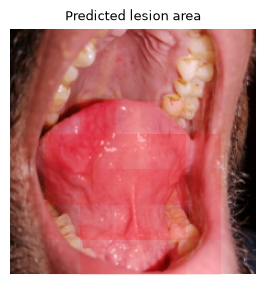

In [19]:
# Example: a test image, with that patient's own details from the patient-wise table.
sample = test_df.iloc[0]
if sample["patient_id"] in patients.index:
    h = patients.loc[sample["patient_id"]]
    details = dict(tobacco=h["Smoking"], betel=h["Chewing_Betel_Quid"], alcohol=h["Alcohol"],
                   age=h["Age"], gender=h["Gender"])
else:
    details = {}

print("Image:", sample["Image Name"], "| true class:", sample["Category"])
_ = predict_full(sample["path"], box=sample["box"], **details)

## Cross-validation

One test split has only about 26 cancer photos, so its scores move by several points from run to
run. For steadier numbers the whole procedure is repeated here on 5 different patient-level splits:
each photo is used for testing exactly once, and the table reports the mean and the spread
(standard deviation) over the 5 folds. Fold 1 is the split used above.

In [20]:
def free_memory():
    gc.collect()
    if keras.backend.backend() == "torch":
        torch.cuda.empty_cache()


if RUN_CV:
    cv_rows = []
    folds = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    for fold, (rest_idx, test_idx) in enumerate(
            folds.split(img_data, img_data["label"], groups=img_data["patient_id"]), start=1):
        fold_test = img_data.iloc[test_idx].reset_index(drop=True)
        fold_train, fold_val = group_split(img_data.iloc[rest_idx].reset_index(drop=True), 5, SEED)
        fold_classes = np.unique(fold_train["label"])
        fold_weights = compute_class_weight("balanced", classes=fold_classes, y=fold_train["label"].to_numpy())
        fold_class_weight = {int(c): float(w) for c, w in zip(fold_classes, fold_weights)}
        fold_train_ds = make_dataset(fold_train, training=True, class_weight=fold_class_weight)
        fold_val_ds, fold_test_ds = make_dataset(fold_val), make_dataset(fold_test)

        proba = {}
        for name in BACKBONES:
            model, _, _ = train_two_stage(name, fold_train_ds, fold_val_ds, verbose=0)
            proba[name] = predict_proba(model, fold_test_ds)
            del model
            free_memory()
        proba["Ensemble"] = sum(proba.values()) / len(proba)

        for name, p in proba.items():
            row = {"fold": fold, "model": name, **scores(fold_test["label"].to_numpy(), p)}
            cv_rows.append(row)
            print(f"fold {fold} {name:12s} accuracy {row['accuracy']:.3f}  macro-F1 {row['macro_f1']:.3f}"
                  f"  OCA recall {row['OCA_recall']:.3f}  referral AUC {row['referral_AUC']:.3f}"
                  f"  OCA AUC {row['OCA_AUC']:.3f}")
        del fold_train_ds, fold_val_ds, fold_test_ds
        free_memory()

    cv_df = pd.DataFrame(cv_rows)
    metric_names = ["accuracy", "macro_f1", "OCA_recall", "referral_AUC", "OCA_AUC"]
    cv_summary = cv_df.groupby("model", sort=False)[metric_names].agg(["mean", "std"]).round(3)
    print(f"\n{CV_FOLDS}-fold cross-validation (mean and standard deviation over folds):")
    print(cv_summary.to_string())
else:
    print("Cross-validation skipped (no GPU). Set ORAL_CV=1 to run it anyway - it takes many hours on a CPU.")

fold 1 MobileNetV2  accuracy 0.548  macro-F1 0.560  OCA recall 0.731  referral AUC 0.742  OCA AUC 0.940
fold 1 DenseNet121  accuracy 0.583  macro-F1 0.561  OCA recall 0.654  referral AUC 0.776  OCA AUC 0.896
fold 1 Ensemble     accuracy 0.595  macro-F1 0.589  OCA recall 0.731  referral AUC 0.768  OCA AUC 0.938
fold 2 MobileNetV2  accuracy 0.658  macro-F1 0.678  OCA recall 0.846  referral AUC 0.856  OCA AUC 0.967
fold 2 DenseNet121  accuracy 0.677  macro-F1 0.647  OCA recall 0.731  referral AUC 0.841  OCA AUC 0.886
fold 2 Ensemble     accuracy 0.682  macro-F1 0.684  OCA recall 0.808  referral AUC 0.857  OCA AUC 0.962
fold 3 MobileNetV2  accuracy 0.558  macro-F1 0.516  OCA recall 0.423  referral AUC 0.757  OCA AUC 0.885
fold 3 DenseNet121  accuracy 0.562  macro-F1 0.515  OCA recall 0.423  referral AUC 0.791  OCA AUC 0.898
fold 3 Ensemble     accuracy 0.570  macro-F1 0.527  OCA recall 0.423  referral AUC 0.788  OCA AUC 0.904
fold 4 MobileNetV2  accuracy 0.657  macro-F1 0.595  OCA recall 0